<a href="https://colab.research.google.com/github/spshirodkar03/CSL701-CE44_Machine--Learning-lab/blob/main/Experiments/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name :Sneha Prasad Shirodkar

Batch :CE03


Roll Number :CE44



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder

# Load the dataset
df = pd.read_csv('/content/palmerpenguins_extended.csv')
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (3430, 11)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [ ]:
# Drop rows with missing values (mapped to the correct dataset column names)
df_cleaned = df.dropna(subset=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'species'])

# Select Features and Target
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df_cleaned[features]
y = df_cleaned['species']

# Encode categorical target using LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Preprocessed Features shape:", X.shape)
print("Classes encoded:", dict(zip(le.classes_, le.transform(le.classes_))))

Preprocessed Features shape: (3430, 4)
Classes encoded: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [ ]:
# Split data into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2744, 4)
Testing set shape: (686, 4)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [ ]:
# Initialize Decision Tree Classifier
cart_model = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)

# Fit on training data
cart_model.fit(X_train, y_train)

# Predict on testing data
y_pred_cart = cart_model.predict(X_test)
print("CART Model training completed.")

CART Model training completed.


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

In [ ]:
# Evaluate CART model performance
accuracy_cart = accuracy_score(y_test, y_pred_cart)
print(f"CART Classification Accuracy: {accuracy_cart * 100:.2f}%\n")

print("Confusion Matrix:")
cm_cart = confusion_matrix(y_test, y_pred_cart)
print(cm_cart)
print("\nClassification Report:")
print(classification_report(y_test, y_pred_cart, target_names=le.classes_))

CART Classification Accuracy: 56.71%

Confusion Matrix:
[[209   2 101]
 [ 66   3  56]
 [ 68   4 177]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686



# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


In [ ]:
# 1. Visualize Tree Structure
plt.figure(figsize=(20, 10))
plot_tree(cart_model, feature_names=features, class_names=le.classes_, filled=True, rounded=True, fontsize=10)
plt.title("CART Decision Tree Structure")
plt.show()

# 2. Select 2-D Features and Train 2D Model
X_2d = df_cleaned[['bill_length_mm', 'flipper_length_mm']]
y_2d = y_encoded

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d
)

cart_model_2d = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart_model_2d.fit(X_train_2d, y_train_2d)

# 3. Plot Decision Boundary function for reference helper
def plot_decision_regions(X_data, y_data, classifier, title):
    x_min, x_max = X_data.iloc[:, 0].min() - 1, X_data.iloc[:, 0].max() + 1
    y_min, y_max = X_data.iloc[:, 1].min() - 1, X_data.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 1.0))

    Z = classifier.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    sns.scatterplot(x=X_data.iloc[:, 0], y=X_data.iloc[:, 1], hue=le.inverse_transform(y_data), palette='coolwarm', edgecolor='k')
    plt.title(title)
    plt.xlabel(X_data.columns[0])
    plt.ylabel(X_data.columns[1])
    plt.legend(title='Species')

plt.figure(figsize=(10, 6))
plot_decision_regions(X_test_2d, y_test_2d, cart_model_2d, "CART Decision Boundary (Axis-aligned Rectangular Splits)")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

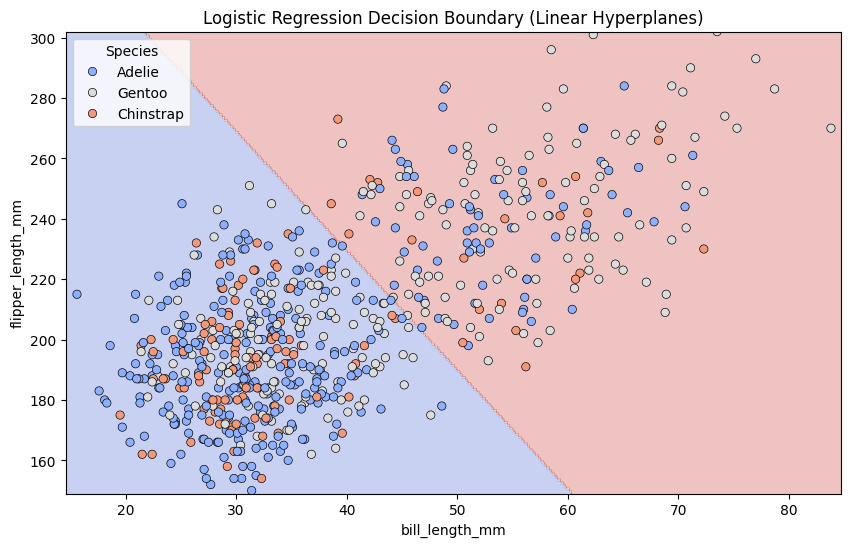

In [ ]:
X_2d = df_cleaned[['bill_length_mm', 'flipper_length_mm']]
y_2d = y_encoded

X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y_2d, test_size=0.2, random_state=42, stratify=y_2d
)

def plot_decision_regions(X_data, y_data, classifier, title):
    x_min, x_max = X_data.iloc[:, 0].min() - 1, X_data.iloc[:, 0].max() + 1
    y_min, y_max = X_data.iloc[:, 1].min() - 1, X_data.iloc[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 1.0))

    # Convert NumPy array to DataFrame with feature names to prevent Scikit-Learn warnings
    grid_points = pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=X_data.columns)
    Z = classifier.predict(grid_points)
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    sns.scatterplot(x=X_data.iloc[:, 0], y=X_data.iloc[:, 1], hue=le.inverse_transform(y_data), palette='coolwarm', edgecolor='k')
    plt.title(title)
    plt.xlabel(X_data.columns[0])
    plt.ylabel(X_data.columns[1])
    plt.legend(title='Species')

# Train Logistic Regression on 2D data
logreg_model_2d = LogisticRegression(max_iter=1000, random_state=42)
logreg_model_2d.fit(X_train_2d, y_train_2d)

# Visualize Logistic Regression Decision Boundary
plt.figure(figsize=(10, 6))
plot_decision_regions(X_test_2d, y_test_2d, logreg_model_2d, "Logistic Regression Decision Boundary (Linear Hyperplanes)")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


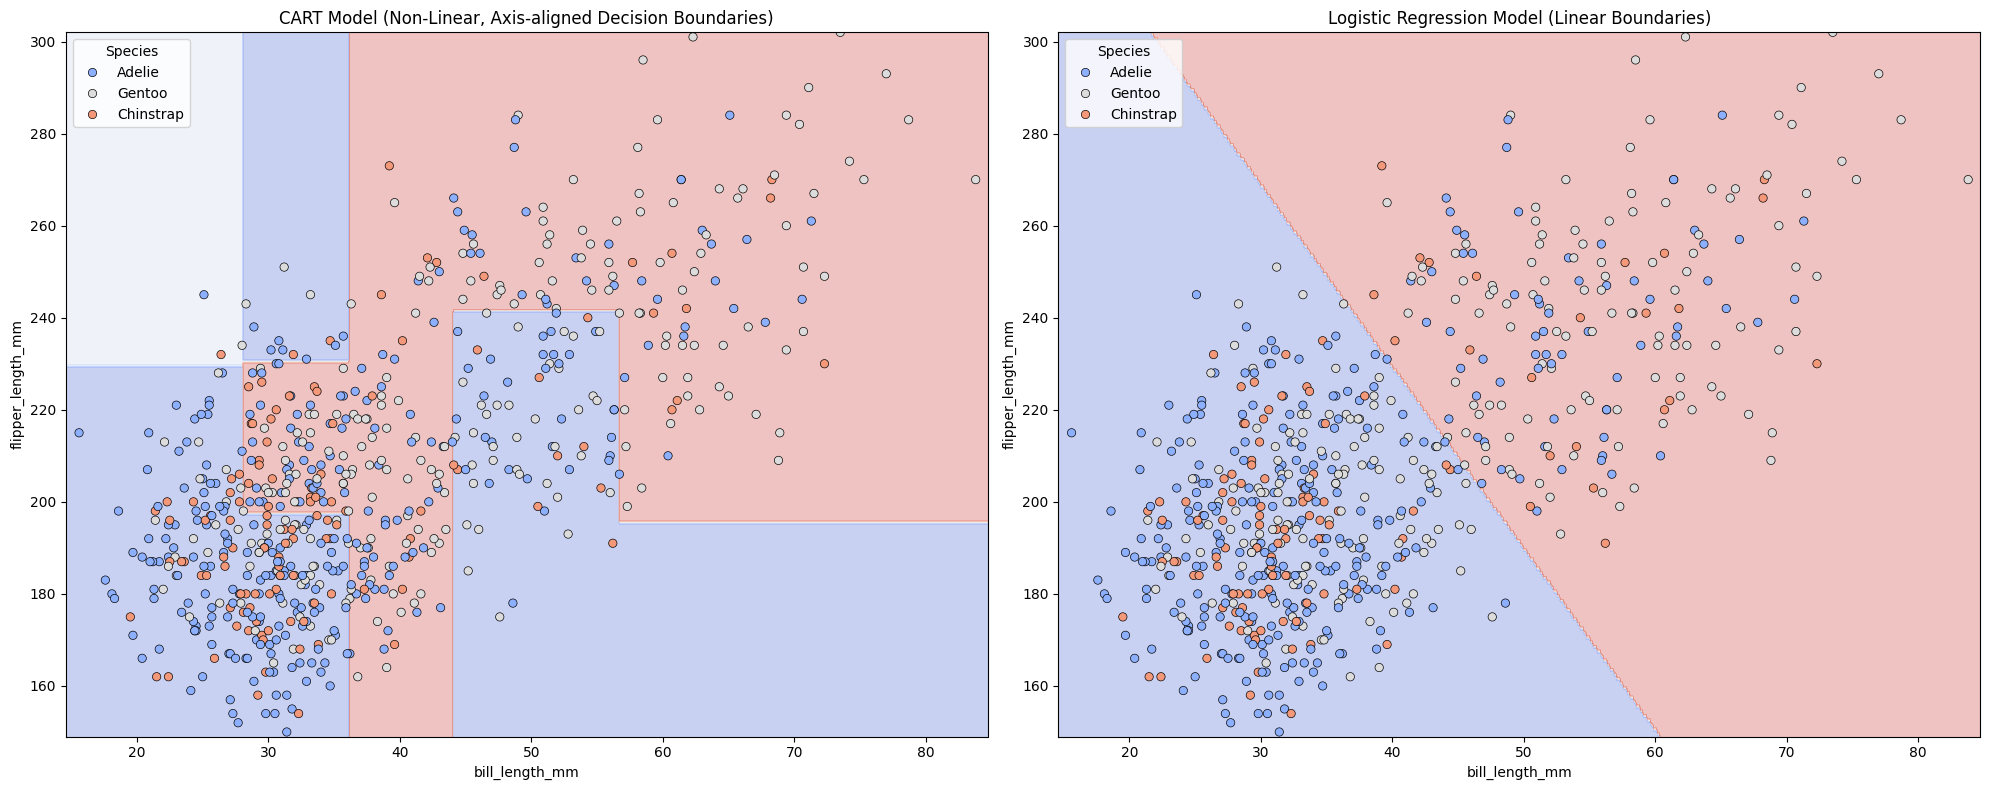

In [ ]:
# Side-by-side Decision Boundary comparison
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Plot CART on left
plt.subplot(1, 2, 1)
plot_decision_regions(X_test_2d, y_test_2d, cart_model_2d, "CART Model (Non-Linear, Axis-aligned Decision Boundaries)")

# Plot Logistic Regression on right
plt.subplot(1, 2, 2)
plot_decision_regions(X_test_2d, y_test_2d, logreg_model_2d, "Logistic Regression Model (Linear Boundaries)")

plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

# Compare performance on 2D datasets
y_pred_cart_2d = cart_model_2d.predict(X_test_2d)
y_pred_logreg_2d = logreg_model_2d.predict(X_test_2d)

print("=== CART Decision Tree (2D) ===")
print(f"Accuracy: {accuracy_score(y_test_2d, y_pred_cart_2d) * 100:.2f}%")
print(classification_report(y_test_2d, y_pred_cart_2d, target_names=le.classes_))

print("=== Logistic Regression (2D) ===")
print(f"Accuracy: {accuracy_score(y_test_2d, y_pred_logreg_2d) * 100:.2f}%")
print(classification_report(y_test_2d, y_pred_logreg_2d, target_names=le.classes_))